# Phase 3b: Checking the rasters, choosing the speckle filter, and maps

P3a asked Google Earth Engine to make the rasters. This notebook opens what came back and answers three questions before we build any features in Phase 4:

1. **Which speckle filter should the main Sentinel-1 export use?** (Steps 1 to 4)
2. **Are the files correct?** Right number of files, sensible values, enough cloud-free looks, and pixels that sit on the fields. (Steps 5 to 7)
3. **What does the study area look like?** Maps for the thesis and slides, all in one style. (Steps 8 to 12)

Part B (Steps 13 to 15) checks the main Sentinel-1 export (P3a Step 9, filter `leesigma`).

**Before you run**
- Download the whole Google Drive folder `thesis_phase3` and put every file in `data/raster/` (no sub-folders). Do not push this folder to GitHub.
- If GEE split a big file into pieces (names ending in `-0000000000-0000000000.tif`), leave them as they are. The notebook joins them the first time.
- If you have `data/boundaries/latur_boundaries_2001.gpkg`, the maps draw the district and taluka lines. Without it the maps still work.

**Outputs**: tables in `results/phase3/`, figures in `reports/figures/phase3/`. No farmer details are printed or saved; fields are named only by `uid`.

## Step 0: Setup and file list

Loads the fields (`yield_spatial_v2.gpkg`), the 183 hold-out fields from Phase 5 and the three context boxes from P3a. Then it checks that every file P3a should have made is in `data/raster/`, and how big they are.

Expected: 54 rasters (3 filter-test boxes, 24 Sentinel-2 field files, 12 NDVI box files, 12 MODIS/ERA5/CHIRPS files, DEM, SoilGrids, WorldCover) and 7 tables (6 filter field-mean tables and the Sentinel-2 clear table).

**Found:** all 61 files are present (54 rasters and 7 tables), 1.06 GB in total. Nothing is missing.

In [1]:
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio.merge import merge
from rasterio.features import rasterize
from rasterio.windows import from_bounds
from scipy import ndimage, stats
warnings.filterwarnings("ignore")

here = Path.cwd()
ROOT = here if (here / "data" / "raw").exists() else here.parent
RASTER = ROOT / "data" / "raster"                      # put the whole Google Drive folder thesis_phase3 here
DATA2 = ROOT / "data" / "processed_v2"
OUT = ROOT / "results" / "phase3"; OUT.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "reports" / "figures" / "phase3"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

f = gpd.read_file(DATA2 / "yield_spatial_v2.gpkg")                       # 1,202 fields, EPSG:32643
holdout = set(pd.read_csv(ROOT / "results" / "phase5" / "holdout_v2.csv")["uid"])
boxes = gpd.read_file(OUT / "P3_context_boxes.gpkg")
VARIANTS = ["none", "focal30", "refinedlee", "leesigma", "gammamap", "quegan"]
YEARS, MONTHS = [2022, 2023, 2024, 2025], [6, 7, 8, 9, 10, 11]

def find(stem):
    """Path of one exported file. GEE splits very large exports into tiles (stem-0000000000-0000000000.tif);
    those are merged into one file the first time."""
    one = RASTER / f"{stem}.tif"
    if one.exists(): return one
    parts = sorted(RASTER.glob(f"{stem}-*.tif"))
    if not parts: return None
    srcs = [rasterio.open(p) for p in parts]; arr, tr = merge(srcs); prof = srcs[0].profile
    desc = srcs[0].descriptions; [s.close() for s in srcs]
    prof.update(height=arr.shape[1], width=arr.shape[2], transform=tr, compress="lzw")
    with rasterio.open(one, "w", **prof) as d:
        d.write(arr)
        for i, n in enumerate(desc): d.set_band_description(i + 1, n or f"band{i + 1}")
    return one

def band_names(src, default=None):
    d = list(src.descriptions)
    return d if all(d) else (default or [f"band{i + 1}" for i in range(src.count)])

expected = ([f"S1test_20250801_{b}_lin_10m" for b in boxes["box"]] +
            [f"S2_{y}_{m:02d}_fields_10m" for y in YEARS for m in MONTHS] +
            [f"S2NDVI_{y}_{b}_10m" for y in YEARS for b in boxes["box"]] +
            [f"{p}_{y}_{r}" for y in YEARS for p, r in [("MODIS", "500m"), ("ERA5", "10km"), ("CHIRPS", "5km")]] +
            ["DEM_terrain_30m", "SOILGRIDS_250m", "WORLDCOVER_2021_10m"])
tables = [f"S1test_2025_fieldmeans_{v}.csv" for v in VARIANTS] + ["S2_clear_per_field_month.csv"]
rows = []
for s in expected:
    p = find(s); rows.append({"file": s + ".tif", "found": p is not None, "MB": round(p.stat().st_size / 1e6, 1) if p else np.nan})
for t in tables:
    p = RASTER / t; rows.append({"file": t, "found": p.exists(), "MB": round(p.stat().st_size / 1e6, 2) if p.exists() else np.nan})
inv = pd.DataFrame(rows); inv.to_csv(OUT / "P3b_inventory.csv", index=False)
print(f"found {inv['found'].sum()} of {len(inv)} files | total {inv['MB'].sum() / 1000:.2f} GB")
if (~inv["found"]).any(): print("missing:\n" + inv.loc[~inv["found"], "file"].to_string(index=False))

found 61 of 61 files | total 1.06 GB


# Part A1: Choosing the Sentinel-1 speckle filter

**Why we need this.** Radar images look grainy. This grain is called **speckle**: every pixel is a mix of many small echoes that add up or cancel out by chance, so two pixels of the same field can differ by several dB. Our fields are small (about 1 ha, around 100 pixels), so speckle matters. A filter smooths it out, but too much smoothing blurs field borders and mixes a field with its neighbours.

We exported one date (1 August 2025) in six versions: `none` (no filter), `focal30` (the simple 30 m average used in v1), `refinedlee`, `leesigma`, `gammamap` (three standard filters, 5 x 5 pixel window) and `quegan` (uses 10 earlier dates as well as the window, so it can smooth more without blurring). The filter code is Mullissa et al. (2021).

We judge them on four things, then pick the best overall:

| Step | What it measures | Good filter |
|---|---|---|
| 1 | ENL: how smooth a uniform area becomes | high |
| 1 | Edge ratio: do field borders still stand out? | high |
| 1 | Field contrast: can neighbouring fields still be told apart? | high |
| 2 | Picture: does it look right to the eye? | judged by you |
| 3 | Link with yield: does the field value still relate to yield? | high |

## Step 1: Filter quality (ENL, edge ratio, field contrast)

Done on the one-date image of each of the three context boxes, for VV and VH.

- **ENL (equivalent number of looks)** = mean² / variance inside a uniform patch. It says how many independent looks the pixel is worth. An unfiltered Sentinel-1 image is about 4 to 5; a stronger filter gives a higher number. To be fair, the patches are the same for every filter: the 1% of 9 x 9 pixel windows that are the most uniform in the **unfiltered** image.
- **Edge ratio** = average change between neighbouring pixels on field borders, divided by the same inside fields (in dB). Without a filter the inside is so noisy that borders hardly stand out (ratio near 1). A good filter calms the inside but keeps the border step, so the ratio goes up. A filter that blurs everything pulls it back down.
- **Field contrast** = how much field averages differ from each other, divided by how much pixels vary inside a field. Higher means each field gets a cleaner, more distinct value. Fields with fewer than 10 inside pixels (after shrinking 10 m from the border) are left out.

Results are averaged over the three boxes. Saved: `P3b_filter_quality.csv`.

**Found:**
- Every filter makes the image smoother than no filter (VH ENL: none 12, refinedlee 31, quegan 34, gammamap 65, leesigma 72, focal30 84).
- Edge ratio (VH): none 1.00, refinedlee 1.02, focal30 1.04, leesigma 1.08, quegan 1.08, gammamap 1.09. All values are close to 1: on 1 August most fields look like their neighbours (soybean next to soybean), so borders stand out little in any version.
- Field contrast (VH): none 0.78, refinedlee 1.03, quegan 1.13, gammamap 1.25, leesigma 1.36, focal30 1.47.
- focal30 is the smoothest but keeps edges worst of the five filters. leesigma and gammamap give the best balance of smoothness and edges.
- VV gives the same order as VH.

In [9]:
# (a) ENL and edge keeping, on the one-date test image of each context box (linear power)
def enl(a):                                   # equivalent number of looks = mean^2 / variance (higher = less speckle)
    return a.mean() ** 2 / a.var()

rows, pics = [], {}
for _, b in boxes.iterrows():
    p = find(f"S1test_20250801_{b['box']}_lin_10m")
    if p is None: continue
    with rasterio.open(p) as src:
        names = band_names(src, [f"{pol}_{v}" for v in VARIANTS for pol in ["VV", "VH"]])
        img = {n: src.read(i + 1).astype("float64") for i, n in enumerate(names)}
        tr, shape = src.transform, (src.height, src.width)
    # uniform areas: the 9 x 9 windows with the lowest variation in the UNFILTERED image (lowest 1%),
    # the same windows for every filter, so the comparison is fair
    flds = f[f.intersects(b.geometry)]
    inside = rasterize([(g, 1) for g in flds.geometry], out_shape=shape, transform=tr, dtype="uint8")
    lab = rasterize([(g, i + 1) for i, g in enumerate(flds.geometry.buffer(-10))], out_shape=shape, transform=tr)   # field interiors
    border = (ndimage.binary_dilation(inside, iterations=1) ^ ndimage.binary_erosion(inside, iterations=1))   # 2-pixel ring on field edges
    for pol in ["VV", "VH"]:
        ref = img[f"{pol}_none"]
        ok = np.isfinite(ref) & (ref > 0)
        m = ndimage.uniform_filter(np.where(ok, ref, 0), 9); m2 = ndimage.uniform_filter(np.where(ok, ref ** 2, 0), 9)
        cv = np.sqrt(np.clip(m2 - m ** 2, 0, None)) / np.where(m > 0, m, np.nan)
        cv[ndimage.uniform_filter(ok.astype(float), 9) < 1] = np.nan
        cv = cv[4:-4:9, 4:-4:9]                                            # non-overlapping windows
        cut = np.nanpercentile(cv, 1); wins = np.argwhere(cv <= cut)
        for v in VARIANTS:
            a = img.get(f"{pol}_{v}")
            if a is None: continue
            e = [enl(a[r * 9:(r + 1) * 9, c * 9:(c + 1) * 9]) for r, c in wins]
            # edge sharpness: change between neighbouring pixels ON field borders divided by the change INSIDE fields (dB).
            # Speckle makes the inside noisy (ratio near 1); a good filter calms the inside but keeps the border step (ratio well above 1)
            db = 10 * np.log10(np.where(a > 0, a, np.nan))
            grad = np.zeros_like(db); grad[:-1, :-1] = np.abs(np.diff(db, axis=1))[:-1, :] + np.abs(np.diff(db, axis=0))[:, :-1]
            edge = np.nanmean(grad[border]) / np.nanmean(grad[(lab > 0) & ~border])
            # field contrast: how different neighbouring fields look after filtering (between-field SD / within-field SD)
            dd = pd.DataFrame({"lab": lab.ravel(), "v": db.ravel()}); dd = dd[(dd["lab"] > 0) & np.isfinite(dd["v"])]
            gm = dd.groupby("lab")["v"].agg(["mean", "std", "size"]); gm = gm[gm["size"] >= 10]
            rows.append({"box": b["box"], "pol": pol, "filter": v, "ENL_median": np.median(e), "edge_ratio": edge,
                         "field_contrast": gm["mean"].std() / gm["std"].mean(), "fields": len(gm)})
        if b["box"] == "westlatur" or not pics:                             # keep one box in memory for the picture in Step 2
            pics = {b["box"]: ({k: x.astype("float32") for k, x in img.items()}, tr, flds)}
    del img
fq = pd.DataFrame(rows)
fq.to_csv(OUT / "P3b_filter_quality.csv", index=False)
summ = fq.groupby(["filter", "pol"])[["ENL_median", "edge_ratio", "field_contrast"]].mean().unstack("pol").reindex(VARIANTS)
print("averaged over the 3 boxes. ENL: higher = less speckle. Edge ratio: higher = field borders stand out more than the inside. Field contrast: higher = fields easier to tell apart")
print(summ.round(2).to_string())

averaged over the 3 boxes. ENL: higher = less speckle. Edge ratio: higher = field borders stand out more than the inside. Field contrast: higher = fields easier to tell apart
           ENL_median        edge_ratio       field_contrast      
pol                VH     VV         VH    VV             VH    VV
filter                                                            
none            12.15  13.76       1.00  1.03           0.78  0.80
focal30         84.45  86.38       1.04  1.05           1.47  1.52
refinedlee      31.39  34.61       1.02  1.03           1.03  1.05
leesigma        72.17  77.50       1.08  1.07           1.36  1.36
gammamap        65.23  69.02       1.09  1.05           1.25  1.30
quegan          33.54  40.45       1.08  1.04           1.13  1.20


## Step 2: Look at it

Numbers can miss things like blocky patterns or smeared borders. This shows VH (dB) for all six versions on the same 3 x 3 km piece of the west Latur box, with the field outlines in white. Look for: grain gone inside fields, borders still sharp, no strange shapes. Saved: `P3b_filter_visual.png`.

**Found:** `none` and `refinedlee` are still grainy. `focal30` is blurry: field borders and small dark spots are smeared. `gammamap` shows blocky, painted-looking patches (a known artefact of this filter). `quegan` keeps the finest detail (thin lines stay visible) but is less smooth. `leesigma` is smooth and clean and keeps the shapes.

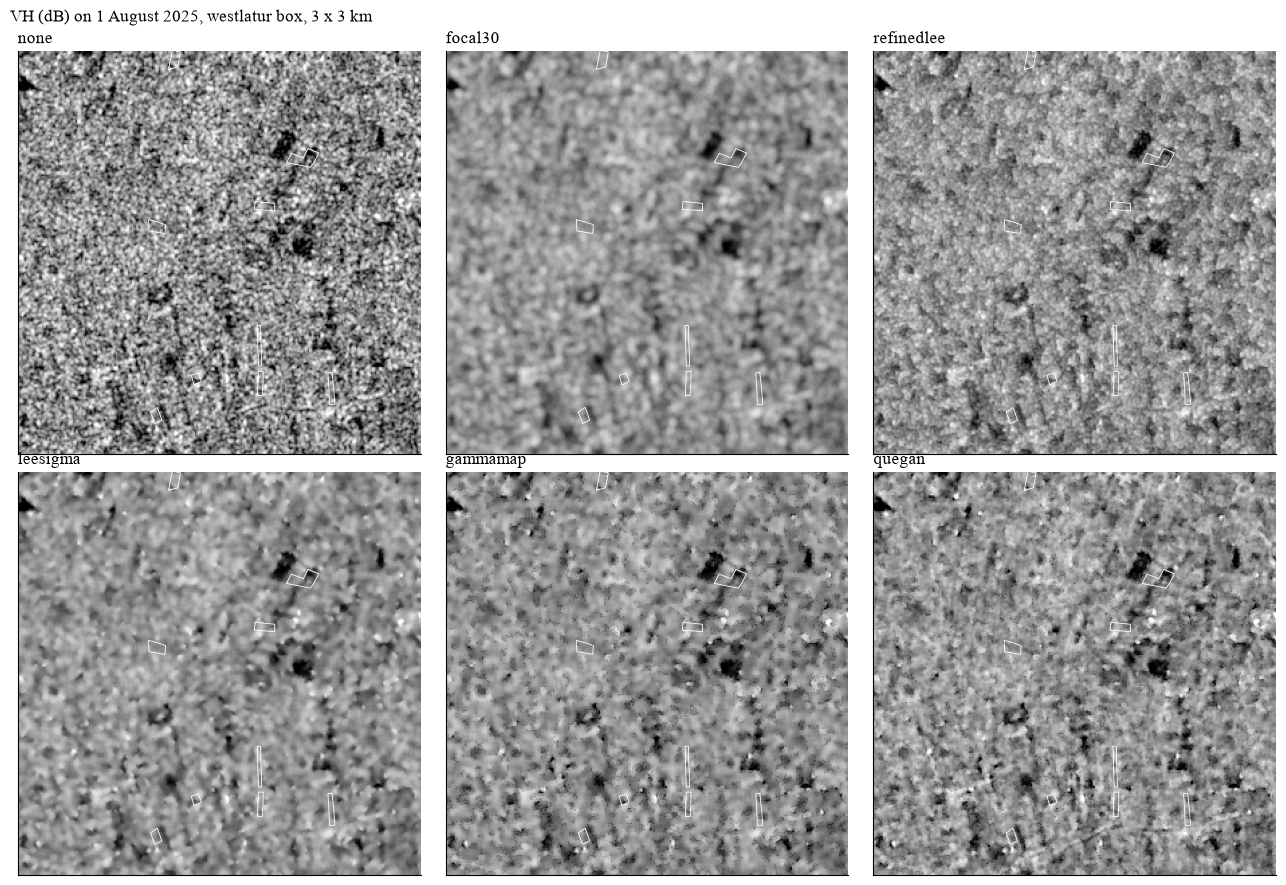

In [10]:
# visual check: VH (dB) of each version, a 3 x 3 km piece of the west Latur box, field outlines in white
name = "westlatur" if "westlatur" in pics else next(iter(pics))
img, tr, flds = pics[name]
H, Wd = img["VH_none"].shape; r0, c0 = H // 2 - 150, Wd // 2 - 150
x0, y0 = tr * (c0, r0); ext = [x0, x0 + 3000, y0 - 3000, y0]
fig, axes = plt.subplots(2, 3, figsize=(13, 9))
for ax, v in zip(axes.ravel(), VARIANTS):
    a = 10 * np.log10(img[f"VH_{v}"][r0:r0 + 300, c0:c0 + 300])
    ax.imshow(a, cmap="gray", vmin=-22, vmax=-10, extent=ext)
    flds.boundary.plot(ax=ax, color="white", lw=0.6)
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3]); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(v, loc="left", fontsize=12)
fig.suptitle(f"VH (dB) on 1 August 2025, {name} box, 3 x 3 km", x=0.01, ha="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "P3b_filter_visual.png", dpi=250, facecolor="white"); plt.show()

## Step 3: Link with yield

For each filter, the field average of VV and VH (from GEE, each month of 2025) is compared with the field's yield using the **Spearman correlation (rho)**: +1 means higher backscatter always goes with higher yield, 0 means no link. Only the 2025 **development fields** are used; the hold-out stays untouched.

This is not a model. It only checks that a filter does not destroy the yield signal. Small differences between filters are normal here, because field averages over about 100 pixels already cancel much of the speckle. Saved: `P3b_filter_yield_link.csv`.

**Found:**
- All six versions give almost the same link with yield: mean |rho| 0.055 to 0.057, and no month above 0.10 (largest: VV in October, about -0.10).
- So the filter hardly matters for field averages, because averaging about 100 pixels already cancels most of the speckle. A soybean study in Brazil (Cunha et al. 2024) found the same.
- One radar value from one month is only weakly linked to yield. Radar will have to work together with the other data; it will not carry the model alone.

In [11]:
# (b) link with yield: Spearman correlation of each field's monthly VV and VH with its yield (2025, development fields only)
y25 = f[(f["year"] == 2025) & ~f["uid"].isin(holdout)][["uid", "crop_yield"]]
rows = []
for v in VARIANTS:
    p = RASTER / f"S1test_2025_fieldmeans_{v}.csv"
    if not p.exists(): continue
    t = pd.read_csv(p).merge(y25, on="uid")
    for pol in ["VV", "VH"]:
        t[pol + "_dB"] = 10 * np.log10(t[pol])
        for m, g in t.groupby("month"):
            g = g.dropna(subset=[pol + "_dB"])
            rho, pv = stats.spearmanr(g[pol + "_dB"], g["crop_yield"])
            rows.append({"filter": v, "pol": pol, "month": m, "fields": len(g), "rho": rho, "p": pv})
link = pd.DataFrame(rows); link.to_csv(OUT / "P3b_filter_yield_link.csv", index=False)
piv = link.pivot_table(index="filter", columns=["pol", "month"], values="rho").reindex(VARIANTS)
print("Spearman rho with yield, 2025 development fields (hold-out excluded)")
print(piv.round(3).to_string())
best = link.assign(a=link["rho"].abs()).groupby("filter")["a"].agg(["mean", "max"]).reindex(VARIANTS)
print("\nmean and max |rho| over months and polarisations:"); print(best.round(3).to_string())

Spearman rho with yield, 2025 development fields (hold-out excluded)
pol            VH                                        VV                                   
month          6      7      8      9      10     11     6      7      8      9      10     11
filter                                                                                        
none       -0.046 -0.035 -0.053 -0.006 -0.066 -0.089 -0.043 -0.063 -0.066  0.037 -0.096 -0.058
focal30    -0.036 -0.041 -0.062  0.002 -0.066 -0.090 -0.035 -0.073 -0.081  0.030 -0.098 -0.065
refinedlee -0.040 -0.038 -0.057 -0.004 -0.068 -0.089 -0.038 -0.069 -0.075  0.035 -0.101 -0.062
leesigma   -0.042 -0.038 -0.061 -0.001 -0.066 -0.089 -0.034 -0.070 -0.077  0.036 -0.096 -0.060
gammamap   -0.043 -0.035 -0.067  0.008 -0.067 -0.086 -0.033 -0.071 -0.072  0.034 -0.092 -0.056
quegan     -0.047 -0.034 -0.068  0.006 -0.066 -0.084 -0.033 -0.069 -0.071  0.036 -0.090 -0.054

mean and max |rho| over months and polarisations:
             mean    max


## Step 4: Pick the filter

Each filter gets a rank (1 = best) on ENL, edge ratio, field contrast (all VH, the band most linked to crop growth) and mean |rho| with yield. The ranks are added; the lowest total is the suggestion. Saved: `P3b_filter_choice.csv`.

The suggestion is not automatic. Check it against the picture in Step 2. If the winner looks blurry or blocky, take the next one. Then open P3a, set `FILTER = "..."` in Step 9 and run that cell to start the main Sentinel-1 export.

**Found:**
- The rank sum suggested `focal30` (7), then `leesigma` (10), `gammamap` (11), `quegan` (16), `refinedlee` (17) and `none` (23).
- **Chosen: `leesigma`.** The rank sum favours blurring, because ENL and field contrast both go up when an image is blurred, so smoothing is counted twice; only the edge ratio counts against it, and the yield link is a tie. `focal30` has the weakest edges of the five filters and looks blurry in Step 2. `leesigma` is in the top three on every measure (ENL 72, edge ratio 1.08, field contrast 1.36) and looks clean.
- `FILTER = "leesigma"` was set in P3a Step 9 for the main Sentinel-1 export.

In [12]:
# (c) put the three criteria together: rank the filters (1 = best) on each, then add the ranks
score = pd.DataFrame({
    "ENL (VH)": summ[("ENL_median", "VH")], "edge ratio (VH)": summ[("edge_ratio", "VH")],
    "field contrast (VH)": summ[("field_contrast", "VH")], "mean |rho| with yield": best["mean"]}).reindex(VARIANTS)
ranks = score.rank(ascending=False)
score["rank_sum"] = ranks.sum(axis=1)
score = score.sort_values("rank_sum")
score.to_csv(OUT / "P3b_filter_choice.csv")
print(score.round(3).to_string())
print("\nsuggested filter (lowest rank sum):", score.index[0], "| decide together with the visual check, then set FILTER in P3a Step 9")

            ENL (VH)  edge ratio (VH)  field contrast (VH)  mean |rho| with yield  rank_sum
filter                                                                                     
focal30       84.445            1.040                1.466                  0.057       7.0
leesigma      72.174            1.075                1.356                  0.056      10.0
gammamap      65.229            1.089                1.254                  0.055      11.0
quegan        33.537            1.078                1.133                  0.055      16.0
refinedlee    31.393            1.024                1.032                  0.056      17.0
none          12.153            0.997                0.783                  0.055      23.0

suggested filter (lowest rank sum): focal30 | decide together with the visual check, then set FILTER in P3a Step 9


# Part A2: Are the files correct?

## Step 5: Cloud-free Sentinel-2 looks per month

Sentinel-2 is an optical satellite, so clouds block it. During the monsoon (July, August) many fields get no clear look at all. For each field, year and month, GEE counted the clear looks (Cloud Score+ at least 0.60) and averaged them over the field. Here, a field counts as **seen** in a month if that average is at least 1.

This tells us which Sentinel-2 months we can trust in Phase 4, and why Sentinel-1 (which sees through clouds) matters. Saved: `P3b_s2_clear_share.csv`, `P3b_s2_clear.png`.

**Found** (% of fields with at least one clear look):

| Year | Jun | Jul | Aug | Sep | Oct | Nov |
|---|---|---|---|---|---|---|
| 2022 | 100 | 93 | 56 | 100 | 100 | 100 |
| 2023 | 100 | 15 | 68 | 72 | 100 | 100 |
| 2024 | 81 | 3 | 66 | 93 | 100 | 100 |
| 2025 | 75 | 52 | 45 | 98 | 100 | 100 |

- July is almost blind in 2023 (15%) and 2024 (3%). August is about half (45 to 68%).
- September is mostly clear (93 to 100%, but 72% in 2023), and October and November are always clear.
- So Sentinel-2 covers the peak and harvest of the season for almost every field, and Sentinel-1 radar has to cover July and August, as in other kharif studies in India.

% of fields with at least one clear Sentinel-2 look (field average >= 1)
month     6     7     8      9      10     11
year                                         
2022   100.0  93.0  56.0  100.0  100.0  100.0
2023   100.0  15.0  68.0   72.0  100.0  100.0
2024    81.0   3.0  66.0   93.0  100.0  100.0
2025    75.0  52.0  45.0   98.0  100.0  100.0


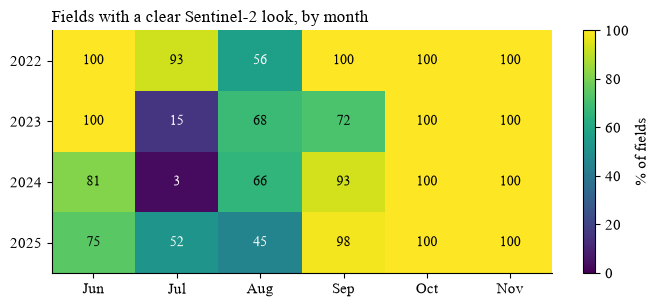

In [13]:
# Sentinel-2: how many clear (cloud-free) looks did each field get per month?
cl = pd.read_csv(RASTER / "S2_clear_per_field_month.csv")
cl["has_clear"] = cl["mean"] >= 1                                     # on average at least one clear look over the field
share = cl.pivot_table(index="year", columns="month", values="has_clear", aggfunc="mean") * 100
share.to_csv(OUT / "P3b_s2_clear_share.csv")
print("% of fields with at least one clear Sentinel-2 look (field average >= 1)")
print(share.round(0).to_string())
fig, ax = plt.subplots(figsize=(7, 3.2))
im = ax.imshow(share.values, cmap="viridis", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(share.shape[1]), [pd.Timestamp(2000, m, 1).strftime("%b") for m in share.columns])
ax.set_yticks(range(share.shape[0]), share.index)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        ax.text(j, i, f"{share.values[i, j]:.0f}", ha="center", va="center", color="white" if share.values[i, j] < 60 else "black", fontsize=10)
plt.colorbar(im, ax=ax, label="% of fields")
ax.set_title("Fields with a clear Sentinel-2 look, by month", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "P3b_s2_clear.png", dpi=250, facecolor="white"); plt.show()

## Step 6: Value check

Every band of every file (except Sentinel-1 test files, NDVI box files and land cover, which are checked elsewhere) is read and compared with a range that makes physical sense: NDVI between -1 and 1, temperature 10 to 40 °C, slope 0 to 60 degrees, and so on. A band is flagged if more than 1% of its pixels fall outside its range, or if it is empty. Big files are read at a reduced size, which is enough for a range check.

A flag means something went wrong in the export (wrong units or scale factor, an empty month). Saved: `P3b_value_check.csv`.

**Found:**
- 500 bands in 38 files checked: **0 problems** (no empty band, no band with more than 1% of values outside its range).
- Typical values fit Latur: temperature 24 °C (maximum 30 °C), VPD 0.64 kPa, rain about 170 to 200 mm per month, soil moisture 0.45, elevation 617 m, slope 2°, TWI 8.6, clay 39%, sand 31%, pH 7.2, soil carbon 9.5 g/kg, LAI 0.8 and FPAR 0.40 (averaged over the season, including bare soil in June), median NDVI 0.34.
- Share of field centres with a Sentinel-2 value follows the same pattern as Step 5 (for example July 2024: 4%, July 2023: 17%). The numbers differ a little from Step 5 because here one point per field is checked, while Step 5 needs the field average to reach at least one clear look.

In [15]:
# value checks: every band of every file, compared with a range that makes physical sense.
# Sentinel-2 field files are 86 x 81 km but have values only on the fields, so they are checked at the field centres
# (reading whole 10 m files 192 times is very slow); the coarse files are small and are read whole.
RANGES = {"NDVI": (-1, 1), "EVI": (-1, 2), "GCVI": (-1, 20), "LSWI": (-1, 1), "NDRE": (-1, 1), "NIRv": (-0.5, 1), "RECI": (-1, 20), "n_clear": (0, 40),
          "LAI": (0, 8), "FPAR": (0, 1), "GPP": (0, 0.2), "PSNNET": (-0.05, 0.2), "T": (10, 40), "TMAX": (15, 45), "VPD": (0, 5),
          "PRECIP": (0, 1500), "AET": (0, 300), "PET": (0, 500), "SM": (0, 0.7), "RAIN": (0, 1500), "ELEV": (300, 900), "SLOPE": (0, 60),
          "ASPECT": (0, 360), "TWI": (-5, 30), "clay": (0, 1000), "sand": (0, 1000), "soc": (0, 1000), "phh2o": (30, 100)}
def key(band): return re.split(r"_(?=\d\d$)|_0-|_5-|_15-|_season", band)[0]
cxy = {yr: [(p.x, p.y) for p in f.loc[f["year"] == yr].geometry.representative_point()] for yr in YEARS}   # a point inside each field
rows = []
files = [s for s in expected if not s.startswith(("S1test", "S2NDVI", "WORLDCOVER"))]
for s in files:
    p = find(s)
    if p is None: continue
    with rasterio.open(p) as src:
        names = band_names(src)
        if s.startswith("S2_"):
            vals = np.array(list(src.sample(cxy[int(s[3:7])]))).astype(float)       # fields x bands
        else:
            vals = src.read().reshape(src.count, -1).T.astype(float)
        for i, n in enumerate(names):
            a = vals[:, i]; a = a[np.isfinite(a)]
            if src.nodata is not None: a = a[a != src.nodata]
            lo, hi = RANGES.get(key(n), (-np.inf, np.inf))
            rows.append({"file": s, "band": n, "valid_values": a.size, "min": a.min() if a.size else np.nan, "median": np.median(a) if a.size else np.nan,
                         "max": a.max() if a.size else np.nan, "outside_range_%": 100 * np.mean((a < lo) | (a > hi)) if a.size else np.nan})
vc = pd.DataFrame(rows); vc.to_csv(OUT / "P3b_value_check.csv", index=False)
s2 = vc["file"].str.startswith("S2_")
bad = vc[(vc["outside_range_%"] > 1) | ((vc["valid_values"] == 0) & ~s2)]
print(f"bands checked: {len(vc)} in {vc['file'].nunique()} files | bands with problems: {len(bad)}")
if len(bad): print(bad.round(3).to_string(index=False))
print("\nSentinel-2: share of field centres with a value (cloudy months are lower, that is expected):")
print(vc[s2 & (vc["band"] == "NDVI")].assign(share=lambda d: d["valid_values"] / d["file"].str[3:7].astype(int).map({y: len(v) for y, v in cxy.items()}) * 100)
      .set_index("file")["share"].round(0).to_string())
print("\nmedian per layer type (all years and months):")
print(vc.assign(layer=vc["band"].map(key)).groupby("layer")["median"].median().round(3).to_string())

bands checked: 500 in 38 files | bands with problems: 0

Sentinel-2: share of field centres with a value (cloudy months are lower, that is expected):
file
S2_2022_06_fields_10m    100.0
S2_2022_07_fields_10m     95.0
S2_2022_08_fields_10m     67.0
S2_2022_09_fields_10m    100.0
S2_2022_10_fields_10m    100.0
S2_2022_11_fields_10m    100.0
S2_2023_06_fields_10m    100.0
S2_2023_07_fields_10m     17.0
S2_2023_08_fields_10m     79.0
S2_2023_09_fields_10m     83.0
S2_2023_10_fields_10m    100.0
S2_2023_11_fields_10m    100.0
S2_2024_06_fields_10m     86.0
S2_2024_07_fields_10m      4.0
S2_2024_08_fields_10m     74.0
S2_2024_09_fields_10m     95.0
S2_2024_10_fields_10m    100.0
S2_2024_11_fields_10m    100.0
S2_2025_06_fields_10m     81.0
S2_2025_07_fields_10m     63.0
S2_2025_08_fields_10m     54.0
S2_2025_09_fields_10m     99.0
S2_2025_10_fields_10m    100.0
S2_2025_11_fields_10m    100.0

median per layer type (all years and months):
layer
AET         92.863
ASPECT     152.198
ELEV      

## Step 7: Do the fields line up with the pixels?

For each year, one Sentinel-2 field file is opened (the clearest month available) and every field polygon is laid on it. We count the 10 m pixels whose centre lies inside the field, and how many of them have a value.

Every field should have values, and very small fields (under 10 pixels) are worth knowing about, because their averages will be noisier. Saved: `P3b_field_pixels.csv`.

**Found:** every field lines up with the pixels and has values. Median pixels per field: 116 (2022), 108 (2023), 85 (2024), 85 (2025). No field has fewer than 10 pixels.

In [16]:
# do the fields line up with the pixels? For each year, share of fields with Sentinel-2 values, and pixels per field
rows = []
for yr in YEARS:
    p = next((find(f"S2_{yr}_{m:02d}_fields_10m") for m in [10, 11, 9, 6, 8, 7] if find(f"S2_{yr}_{m:02d}_fields_10m")), None)   # the clearest month first
    if p is None: continue
    g = f[f["year"] == yr]
    with rasterio.open(p) as src:
        for _, r in g.iterrows():
            win = from_bounds(*r.geometry.bounds, transform=src.transform).round_offsets().round_lengths()
            win = rasterio.windows.Window(win.col_off - 1, win.row_off - 1, win.width + 2, win.height + 2)
            a = src.read(1, window=win, boundless=True, fill_value=np.nan)           # NDVI band
            m = rasterize([(r.geometry, 1)], out_shape=a.shape, transform=src.window_transform(win), all_touched=False)
            rows.append({"uid": r["uid"], "year": yr, "file": p.name, "pixels": int(m.sum()), "with_value": int(np.isfinite(a[m == 1]).sum())})
al = pd.DataFrame(rows); al.to_csv(OUT / "P3b_field_pixels.csv", index=False)
print(al.groupby("year").agg(fields=("uid", "size"), median_pixels=("pixels", "median"), fields_under_10_pixels=("pixels", lambda s: int((s < 10).sum())),
                             fields_with_values=("with_value", lambda s: int((s > 0).sum()))).to_string())

      fields  median_pixels  fields_under_10_pixels  fields_with_values
year                                                                   
2022      55          116.0                       0                  55
2023      58          108.0                       0                  58
2024     323           85.0                       0                 323
2025     766           85.0                       0                 766


# Part A3: Maps

## Step 8: One map style

Every map uses the same frame, so they look consistent in the thesis: title, colour bar, scale bar, north arrow, a km grid (UTM coordinates), district and taluka lines (if the boundary file is there), the data source and the coordinate system (WGS 84 / UTM zone 43N, EPSG:32643). Big rasters are shrunk for display only (to about 2,000 pixels a side); nothing is changed in the files. This cell only defines the functions.

In [2]:
# one map style for every map: title, colour bar, scale bar, north arrow, km grid, CRS and data source
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter
from rasterio.enums import Resampling
CRS_TXT = "WGS 84 / UTM zone 43N (EPSG:32643)"
bnd = ROOT / "data" / "boundaries" / "latur_boundaries_2001.gpkg"
district = gpd.read_file(bnd, layer="latur_district").to_crs(32643) if bnd.exists() else None
talukas = gpd.read_file(bnd, layer="latur_talukas").to_crs(32643) if bnd.exists() else None
with rasterio.open(find("DEM_terrain_30m")) as s: AREA = s.bounds                 # the export area (86 x 81 km)

def read_band(stem, band, max_px=2000, nearest=False):
    """One band of a file, shrunk to at most max_px pixels per side so district maps stay fast. Returns array and extent."""
    with rasterio.open(find(stem)) as src:
        i = band_names(src).index(band) + 1 if isinstance(band, str) else band
        step = max(1, int(np.ceil(max(src.width, src.height) / max_px)))
        a = src.read(i, out_shape=(src.height // step, src.width // step),
                     resampling=Resampling.nearest if nearest else Resampling.average).astype(float)
        if src.nodata is not None: a[a == src.nodata] = np.nan
        b = src.bounds
    return a, [b.left, b.right, b.bottom, b.top]

def map_frame(ax, title, source, bounds=None, scale_km=10):
    """Grid in km, scale bar, north arrow, boundaries, title, source and CRS line."""
    x0, y0, x1, y1 = bounds or AREA
    if talukas is not None: talukas.boundary.plot(ax=ax, color="0.35", lw=0.5)
    if district is not None: district.boundary.plot(ax=ax, color="black", lw=1)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect("equal")
    km = FuncFormatter(lambda v, _: f"{v / 1000:.0f}")
    ax.xaxis.set_major_formatter(km); ax.yaxis.set_major_formatter(km)
    ax.tick_params(labelsize=8); ax.grid(color="0.6", lw=0.3, ls=":")
    ax.set_xlabel("Easting (km)", fontsize=9); ax.set_ylabel("Northing (km)", fontsize=9)
    sx, sy, L = x0 + 0.05 * (x1 - x0), y0 + 0.05 * (y1 - y0), scale_km * 1000
    for k in range(2):                                                                   # black and white scale bar
        ax.add_patch(Rectangle((sx + k * L / 2, sy), L / 2, 0.012 * (y1 - y0), fc="black" if k == 0 else "white", ec="black", lw=0.6, zorder=5))
    ax.text(sx, sy + 0.022 * (y1 - y0), "0", fontsize=7, ha="center", zorder=5)
    ax.text(sx + L, sy + 0.022 * (y1 - y0), f"{scale_km} km", fontsize=7, ha="center", zorder=5)
    ax.annotate("N", xy=(0.95, 0.95), xytext=(0.95, 0.85), xycoords="axes fraction", ha="center", va="center", fontsize=10, fontweight="bold",
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.2), zorder=5)
    ax.set_title(title, loc="left", fontsize=11)
    if source: ax.text(0, -0.13, f"Source: {source} | {CRS_TXT}", transform=ax.transAxes, fontsize=7, color="0.3", va="top")

def raster_map(ax, a, ext, title, source, label, cmap="viridis", vmin=None, vmax=None, bounds=None, scale_km=10, cbar=True):
    im = ax.imshow(a, extent=ext, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    map_frame(ax, title, source, bounds, scale_km)
    if cbar: plt.colorbar(im, ax=ax, shrink=0.75, label=label)
    return im

def fig_source(fig, source):
    """For maps with several panels: one source and CRS line under the whole figure."""
    fig.text(0.01, -0.02, f"Source: {source} | {CRS_TXT}", fontsize=9, color="0.3", va="top")

def save(fig, name):
    fig.savefig(FIG / name, dpi=250, facecolor="white", bbox_inches="tight"); plt.show()

## Step 9: Study area

Every field (one dot at its centre, coloured by year), the 183 hold-out fields (black rings) and the three context boxes. The map frame is the export area (all fields plus 1 km). Saved: `P3b_map_study_area.png`.

**Found:** fields of all four years (55, 58, 323, 766), the 183 hold-out fields and the three context boxes all lie inside the district. The fields form a few dense clusters in the west (around west Latur), the centre and the east, with only a few fields in the south (Killari).

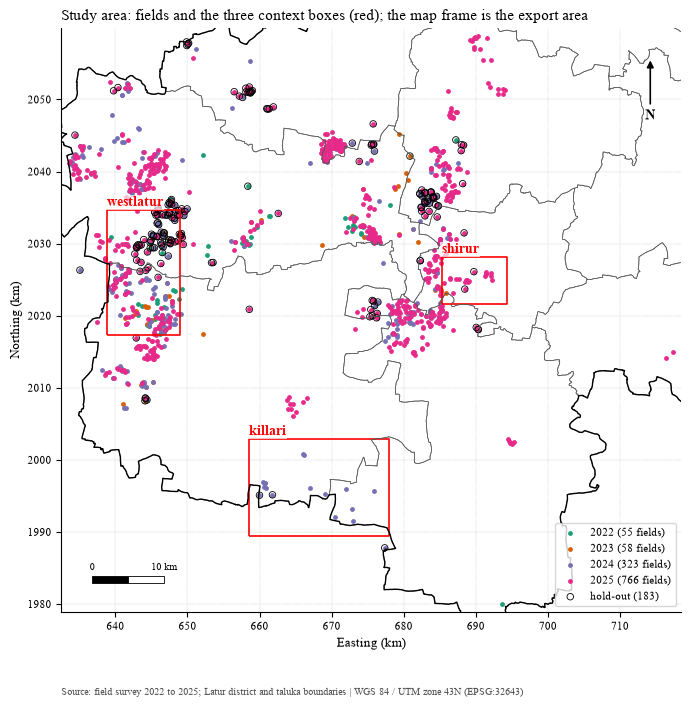

In [18]:
# Map 1: study area. Fields of each year, the three context boxes and the export area
cent = f.copy(); cent["geometry"] = f.geometry.centroid
fig, ax = plt.subplots(figsize=(8, 8))
cols = {2022: "#1b9e77", 2023: "#d95f02", 2024: "#7570b3", 2025: "#e7298a"}
for yr in YEARS:
    g = cent[cent["year"] == yr]; g.plot(ax=ax, color=cols[yr], markersize=6, label=f"{yr} ({len(g)} fields)")
cent[cent["uid"].isin(holdout)].plot(ax=ax, facecolor="none", edgecolor="black", markersize=22, lw=0.6, label=f"hold-out ({len(holdout)})")
boxes.boundary.plot(ax=ax, color="red", lw=1.2)
for _, b in boxes.iterrows():
    x, _, _, y = b.geometry.bounds; ax.text(x, y + 600, b["box"], color="red", fontsize=10, fontweight="bold", bbox=dict(fc="white", ec="none", alpha=0.7, pad=1))
map_frame(ax, "Study area: fields and the three context boxes (red); the map frame is the export area", "field survey 2022 to 2025; Latur district and taluka boundaries")
ax.legend(loc="lower right", fontsize=8, frameon=True)
save(fig, "P3b_map_study_area.png")

## Step 10: Terrain and rain

- **Terrain**: elevation and slope from SRTM (30 m), and the **topographic wetness index (TWI)**, which is high where water collects (low, flat places with a large area draining into them). The colour scale is cut at the 2nd and 98th percentile so a few extreme pixels do not wash out the map.
- **Rain**: total June to November rain per year from CHIRPS (5 km). All four years share one colour scale, so years can be compared by eye.

Saved: `P3b_map_terrain.png`, `P3b_map_rain.png`.

**Found:**
- **Terrain:** most fields are on the higher western plateau (620 to 660 m) and in the central valley. The land is very flat (slope mostly 1 to 5°), so the slope map is partly elevation-data noise and slope is probably a weak feature. TWI shows the drainage lines clearly.
- **Rain (June to November), district mean:** 2022: 1,125 mm (wettest), 2023: 828 mm (driest), 2024: 946 mm, 2025: 1,054 mm.
- Rain total alone does not explain yield: the dry year 2023 and the wet year 2025 both had a median yield of 8.0 q/acre, while the middle year 2024 had the best (9.5). The timing of rain probably matters more than the total, so monthly rain is kept as features.

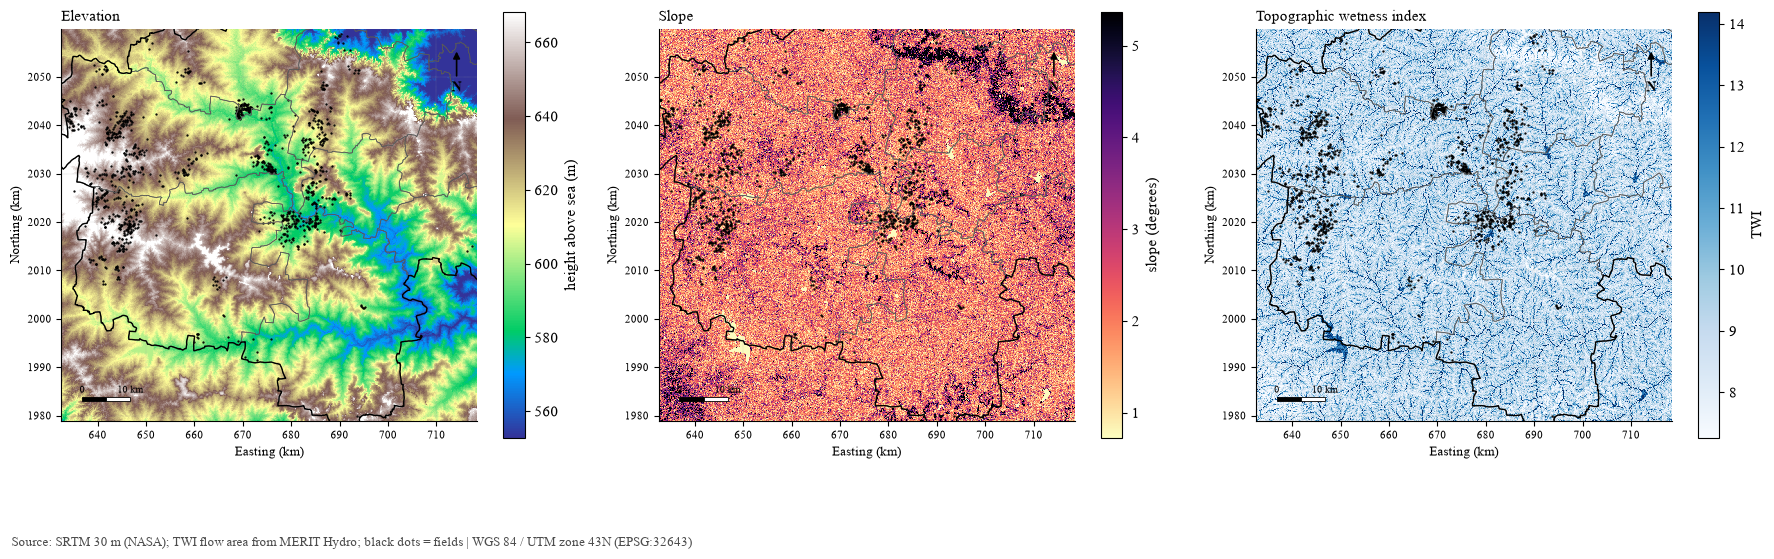

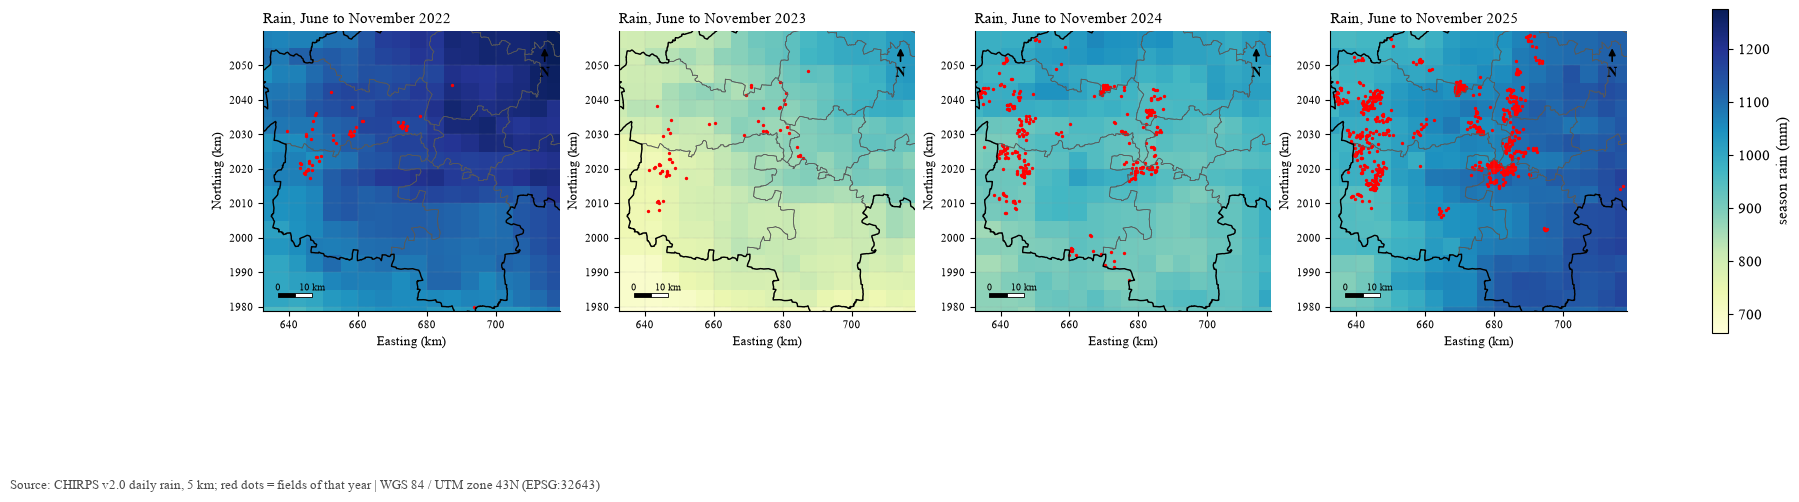

district mean season rain (mm): {2022: 1125, 2023: 828, 2024: 946, 2025: 1054}


In [19]:
# Map 2: terrain. Height, slope and wetness index (TWI: high = water collects there)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (b, lab, cm) in zip(axes, [("ELEV", "height above sea (m)", "terrain"), ("SLOPE", "slope (degrees)", "magma_r"), ("TWI", "TWI", "Blues")]):
    a, ext = read_band("DEM_terrain_30m", b)
    lo, hi = np.nanpercentile(a, [2, 98])
    raster_map(ax, a, ext, {"ELEV": "Elevation", "SLOPE": "Slope", "TWI": "Topographic wetness index"}[b],
               None, lab, cm, lo, hi)
    cent.plot(ax=ax, color="black", markersize=0.4)
fig.tight_layout(); fig_source(fig, "SRTM 30 m (NASA); TWI flow area from MERIT Hydro; black dots = fields"); save(fig, "P3b_map_terrain.png")

# Map 3: season rainfall (June to November) per year, same colour scale for all years
rain = {yr: read_band(f"CHIRPS_{yr}_5km", "RAIN_season") for yr in YEARS if find(f"CHIRPS_{yr}_5km")}
lo = min(np.nanmin(a) for a, _ in rain.values()); hi = max(np.nanmax(a) for a, _ in rain.values())
fig, axes = plt.subplots(1, 4, figsize=(22, 6))
for ax, (yr, (a, ext)) in zip(axes, rain.items()):
    im = raster_map(ax, a, ext, f"Rain, June to November {yr}", None, "", "YlGnBu", lo, hi, cbar=False)
    cent[cent["year"] == yr].plot(ax=ax, color="red", markersize=2)
plt.colorbar(im, ax=axes, shrink=0.7, label="season rain (mm)")
fig_source(fig, "CHIRPS v2.0 daily rain, 5 km; red dots = fields of that year")
save(fig, "P3b_map_rain.png")
print("district mean season rain (mm):", {yr: round(float(np.nanmean(a))) for yr, (a, _) in rain.items()})

## Step 11: Land cover

ESA WorldCover 2021 (10 m), with ESA's own class colours. The legend gives each class's share of the export area. Then we check what class each field's centre falls on: almost all should be cropland. Fields on another class are not wrong (WorldCover makes mistakes on small farms), but it is worth knowing. Saved: `P3b_map_landcover.png`.

**Found:** cropland covers 90.7% of the export area; built-up 2.1% (Latur city is the large red patch), grassland 2.4%, shrubland 2.0%, tree cover 1.7%, water 0.9%, bare 0.2%. At the field centres, **99.2% of fields fall on cropland** (tree cover 0.4%, grassland 0.3%, shrubland 0.1%). So the field outlines match the land cover map.

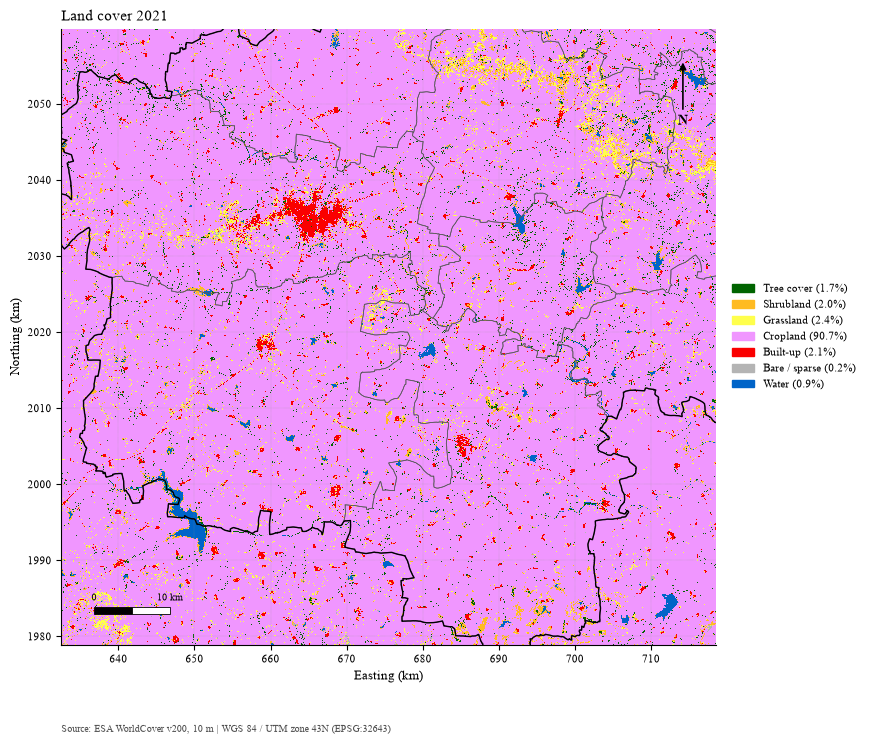

land cover at field centres (% of fields):
Cropland      99.2
Tree cover     0.4
Grassland      0.3
Shrubland      0.1


In [20]:
# Map 4: land cover (ESA WorldCover 2021). Classes and colours are ESA's own
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
WC = {10: ("Tree cover", "#006400"), 20: ("Shrubland", "#ffbb22"), 30: ("Grassland", "#ffff4c"), 40: ("Cropland", "#f096ff"),
      50: ("Built-up", "#fa0000"), 60: ("Bare / sparse", "#b4b4b4"), 70: ("Snow and ice", "#f0f0f0"), 80: ("Water", "#0064c8"),
      90: ("Herbaceous wetland", "#0096a0"), 95: ("Mangroves", "#00cf75"), 100: ("Moss and lichen", "#fae6a0")}
a, ext = read_band("WORLDCOVER_2021_10m", 1, max_px=3000, nearest=True)
codes = sorted(WC); cmap = ListedColormap([WC[c][1] for c in codes]); norm = BoundaryNorm(codes + [101], cmap.N)
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(a, extent=ext, cmap=cmap, norm=norm, interpolation="nearest")
map_frame(ax, "Land cover 2021", "ESA WorldCover v200, 10 m")
share = pd.Series(a[np.isfinite(a)]).value_counts(normalize=True) * 100
ax.legend(handles=[Patch(color=WC[c][1], label=f"{WC[c][0]} ({share.get(c, 0):.1f}%)") for c in codes if share.get(c, 0) > 0.1],
          loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8, frameon=False)
save(fig, "P3b_map_landcover.png")
# what the fields themselves sit on: land cover at each field centre
with rasterio.open(find("WORLDCOVER_2021_10m")) as src:
    lc = np.array([v[0] for v in src.sample([(p.x, p.y) for p in cent.geometry])])
print("land cover at field centres (% of fields):")
print((pd.Series(lc).map(lambda c: WC.get(int(c), ("no data",))[0]).value_counts(normalize=True) * 100).round(1).to_string())

## Step 12: Yield map and monthly NDVI

- **Yield**: one dot per field, coloured by yield (q/acre), one panel per year, same colour scale. This is the map version of the Phase 2 patterns.
- **NDVI**: the six months of 2025 in the west Latur box. NDVI shows how green the plants are (about 0.2 for bare soil, 0.8 for dense crop). Soybean fields should go from low (June, sowing) to high (August, September) and back down (October, November, harvest). Cloudy months may show gaps.

Saved: `P3b_map_yield.png`, `P3b_map_ndvi_months.png`.

**Found:**
- **Yield:** 2024 is the best year (median 9.5 q/acre), then 2022 (9.0), 2023 and 2025 (8.0). In 2025 many fields in the west Latur cluster have low yields. Killari has high yields in 2024, as in Phase 2.
- **NDVI, west Latur 2025:** low in June (bare soil at sowing), cloud holes in July and August, the green peak in September, mixed in October (harvest starts). Many places are still green in November; these are other crops (pigeonpea, rabi sowing), not soybean.
- So for Phase 4, the season peak of Sentinel-2 should be taken only inside the soybean window (about July to October), or other crops will mix in.

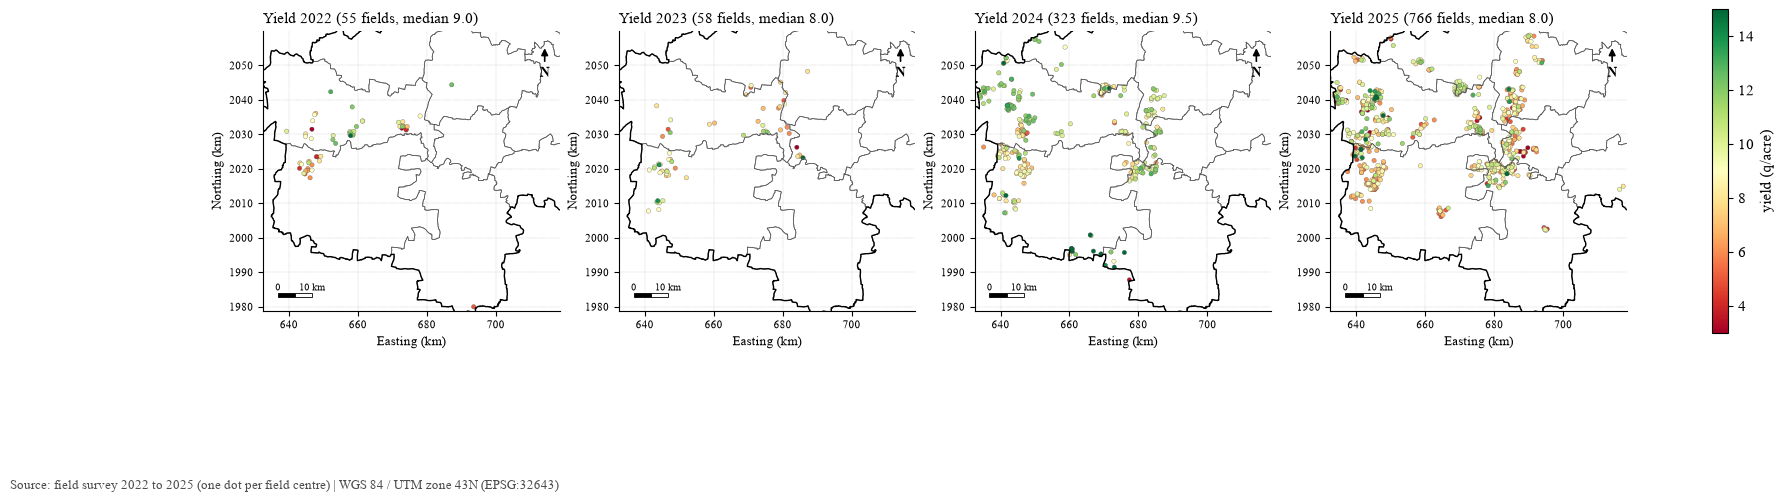

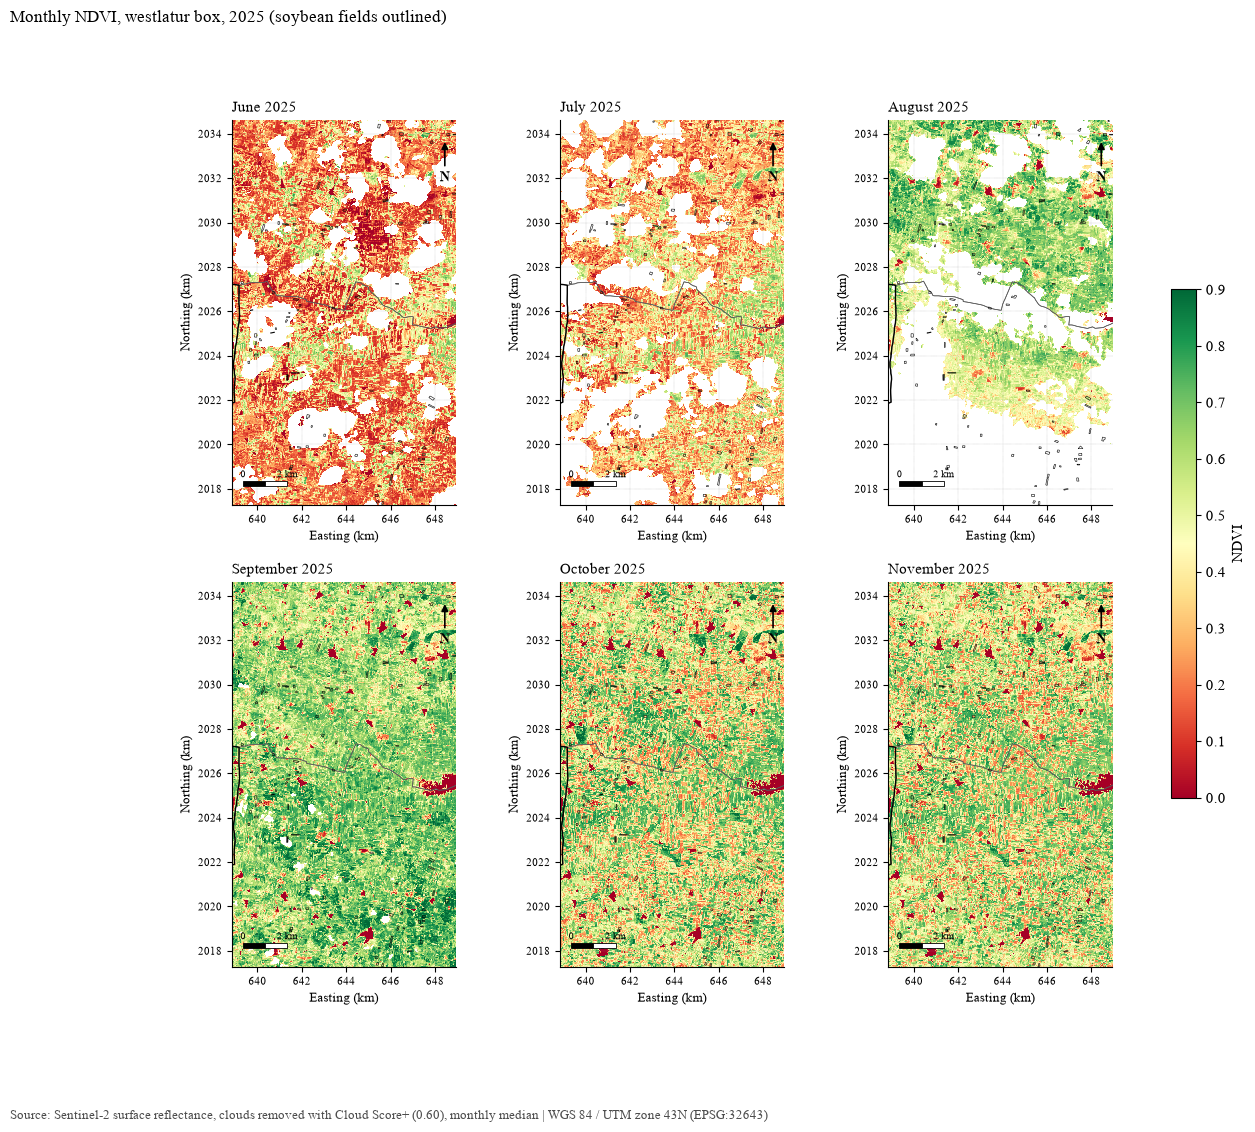

In [21]:
# Map 5: yield of each field, one panel per year, same colour scale
fig, axes = plt.subplots(1, 4, figsize=(22, 6))
lo, hi = np.percentile(f["crop_yield"], [2, 98])
for ax, yr in zip(axes, YEARS):
    g = cent[cent["year"] == yr].sort_values("crop_yield")
    sc = ax.scatter(g.geometry.x, g.geometry.y, c=g["crop_yield"], cmap="RdYlGn", vmin=lo, vmax=hi, s=10, edgecolor="0.3", lw=0.2)
    map_frame(ax, f"Yield {yr} ({len(g)} fields, median {g['crop_yield'].median():.1f})", None)
plt.colorbar(sc, ax=axes, shrink=0.7, label="yield (q/acre)")
fig_source(fig, "field survey 2022 to 2025 (one dot per field centre)")
save(fig, "P3b_map_yield.png")

# Map 6: how the crop greens up and dries, monthly NDVI in one context box (2025)
name = "westlatur" if find("S2NDVI_2025_westlatur_10m") else boxes["box"].iloc[0]
b = boxes.set_index("box").geometry[name].bounds
inbox = f[(f["year"] == 2025) & f.intersects(boxes.set_index("box").geometry[name])]
fig, axes = plt.subplots(2, 3, figsize=(15, 11))
for ax, m in zip(axes.ravel(), MONTHS):
    a, ext = read_band(f"S2NDVI_2025_{name}_10m", f"NDVI_{m:02d}")
    im = raster_map(ax, a, ext, pd.Timestamp(2025, m, 1).strftime("%B 2025"), None,
                    "", "RdYlGn", 0, 0.9, bounds=b, scale_km=2, cbar=False)
    inbox.boundary.plot(ax=ax, color="black", lw=0.4)
fig.colorbar(im, ax=axes, shrink=0.6, label="NDVI")
fig_source(fig, "Sentinel-2 surface reflectance, clouds removed with Cloud Score+ (0.60), monthly median")
fig.suptitle(f"Monthly NDVI, {name} box, 2025 (soybean fields outlined)", x=0.01, ha="left", fontsize=12)
save(fig, "P3b_map_ndvi_months.png")

# Part B: Main Sentinel-1 export

Run these three steps only after P3a Step 9 has finished and the `S1_*` files are in `data/raster/`. Set `FILTER` in the first cell below to the same filter you chose in Step 4. If `FILTER` is `None`, the three cells skip themselves.

## Step 13: Sentinel-1 check

For each year and month: how many images went into the monthly mean (`n_images`: at the 12 day revisit of orbit 63 this should be 2 or 3), the median VV and VH over the field pixels, and the share of pixels outside normal backscatter (VV -30 to 5 dB, VH -35 to 0 dB). Every second pixel is read to keep memory low. Saved: `P3b_s1_check_<filter>.csv`.

**Found:**
- Images per month: median 2 or 3 in every year and month, as expected for one satellite (Sentinel-1A) on orbit 63 with a 12-day repeat. A few field pixels got only 1 image in some months (images_min = 1), probably at the edge of the satellite's strip; those values are noisier.
- Values outside the normal range: about 0% for VV and VH in every month.
- VH follows the soybean season in every year: lowest in June (bare soil, about -18.5 to -20 dB), highest in September (about -14.3 to -15.3 dB; in 2024 August and September are equal at -14.8), then falling to November (harvest, about -17 to -19 dB). VV follows the same pattern (highest about -7.5 to -8.1 dB).

In [ ]:
# PART B: run only after the main Sentinel-1 export (P3a Step 9) is downloaded into data/raster
FILTER = "leesigma"           # the same filter you set in P3a Step 9, for example "refinedlee"
S1_RANGE = {"VV": (-30, 5), "VH": (-35, 0)}                      # normal soil and crop backscatter in dB
s1files = {(yr, m): find(f"S1_{yr}_{m:02d}_{FILTER}_fields_10m") for yr in YEARS for m in MONTHS} if FILTER else {}
partB = FILTER is not None and any(s1files.values())
if not partB:
    print("Part B skipped: set FILTER and download the S1_* files first.")
else:
    rows = []
    for (yr, m), p in s1files.items():
        if p is None: rows.append({"year": yr, "month": m, "found": False}); continue
        with rasterio.open(p) as src:
            nm = band_names(src, ["VV", "VH", "VH_VV", "RVI", "NDPI", "n_images"])
            step = 2                                                            # every 2nd pixel is enough for a check, and halves memory
            rd = lambda b: src.read(nm.index(b) + 1, out_shape=(src.height // step, src.width // step), resampling=Resampling.nearest).astype(float)
            vv, vh, n = rd("VV"), rd("VH"), rd("n_images")
        k = np.isfinite(vv)
        rows.append({"year": yr, "month": m, "found": True, "pixels_with_value": int(k.sum()),
                     "images_min": np.nanmin(n[k]), "images_median": np.nanmedian(n[k]), "images_max": np.nanmax(n[k]),
                     "VV_median": np.median(vv[k]), "VH_median": np.median(vh[k]),
                     "VV_outside_%": 100 * np.mean((vv[k] < S1_RANGE["VV"][0]) | (vv[k] > S1_RANGE["VV"][1])),
                     "VH_outside_%": 100 * np.mean((vh[k] < S1_RANGE["VH"][0]) | (vh[k] > S1_RANGE["VH"][1]))})
        del vv, vh, n
    s1qc = pd.DataFrame(rows); s1qc.to_csv(OUT / f"P3b_s1_check_{FILTER}.csv", index=False)
    print(f"Sentinel-1 ({FILTER}): images per month and backscatter per year and month")
    miss = s1qc[~s1qc["found"]]
    if len(miss): print("missing months:", ", ".join(f"{y}-{m:02d}" for y, m in zip(miss["year"], miss["month"])))
    print(s1qc[s1qc["found"]].drop(columns="found").round(2).to_string(index=False))

Part B skipped: set FILTER and download the S1_* files first.


## Step 14: Same numbers as the test?

The August 2025 field averages from the new raster are compared with the test table of the same filter that GEE made directly in P3a. Both are averages in linear power, so they should agree within about 0.2 dB. A bigger gap would mean a grid or masking problem.

**Found:** the August 2025 field averages from the new file match the GEE test table almost exactly. VV: median difference +0.002 dB, 95% of fields within 0.055 dB. VH: median difference -0.001 dB, 95% of fields within 0.061 dB (766 fields). This is far inside the 0.2 dB limit, so the grid, mask and filter of the main export are correct.

In [23]:
# Same numbers as the test? Field means from the new August 2025 file vs the test table of the same filter (made by GEE directly).
# Both are averages in linear power, so they should agree within about 0.2 dB. A bigger gap means the files or grid are off.
if partB and s1files.get((2025, 8)) and (RASTER / f"S1test_2025_fieldmeans_{FILTER}.csv").exists():
    tt = pd.read_csv(RASTER / f"S1test_2025_fieldmeans_{FILTER}.csv").query("month == 8")
    g = f[f["year"] == 2025]; rows = []
    with rasterio.open(s1files[(2025, 8)]) as src:
        nm = band_names(src, ["VV", "VH", "VH_VV", "RVI", "NDPI", "n_images"])
        for _, r in g.iterrows():
            win = from_bounds(*r.geometry.bounds, transform=src.transform).round_offsets().round_lengths()
            win = rasterio.windows.Window(win.col_off - 1, win.row_off - 1, win.width + 2, win.height + 2)
            m = rasterize([(r.geometry, 1)], out_shape=(int(win.height), int(win.width)), transform=src.window_transform(win)) == 1
            out = {"uid": r["uid"]}
            for pol in ["VV", "VH"]:
                a = src.read(nm.index(pol) + 1, window=win, boundless=True, fill_value=np.nan)[m]
                out[pol + "_new"] = 10 * np.log10(np.nanmean(10 ** (a / 10))) if np.isfinite(a).any() else np.nan
            rows.append(out)
    cmp_ = pd.DataFrame(rows).merge(tt, on="uid")
    for pol in ["VV", "VH"]:
        d = cmp_[pol + "_new"] - 10 * np.log10(cmp_[pol])
        print(f"{pol}: {d.notna().sum()} fields | median difference {d.median():+.3f} dB | 95% of fields within {d.abs().quantile(0.95):.3f} dB")

## Step 15: Sentinel-1 maps

For the west Latur box in 2025:
- **VH month by month** (grey scale, -24 to -10 dB). VH rises as the crop canopy grows, because leaves and stems scatter the radar wave in many directions.
- **Colour mix of VH**: red = June, green = August, blue = October. Bright colours show *when* a place was rough. Soybean fields that grow in August and are harvested by October appear green; places that stay the same all season (towns, bare rock) appear grey.
- **VH/VV at the peak month** (the July to October month with the highest VH): higher (less negative) means more vegetation.
- **Change in VH, September minus June**: red = backscatter went up (crop grew), blue = went down.

Saved: `P3b_map_s1_vh_months_westlatur.png`, `P3b_map_s1_rgb_ratio_change_westlatur.png`.

**Found:**
- VH in the west Latur box rises from June (-17.5 dB) and July (-17.7) to August (-15.7) and peaks in September (-14.9), then falls in October (-16.1) and November (-16.8). Single field shapes are visible as rectangles.
- Change September minus June: most of the area is red (VH up by 2 to 8 dB, crop growth). The blue patches are water (ponds and a reservoir in the east), which reflects the radar away from the satellite and becomes larger after the monsoon.
- VH/VV in September is mostly -5 to -7 dB (vegetation). The low (purple) spots are water and built-up areas.
- A light band across the middle of the change map shows less change. A likely cause is rain on one of the June image dates (wet soil looks brighter in June), but this is not confirmed.

In [24]:
# Sentinel-1 maps for one context box and one year: the season in VH, a colour composite, the VH/VV ratio and the change
if partB:
    name, yr = "westlatur", 2025
    stem = f"S1_{yr}_{name}_{FILTER}_10m"
    if find(stem) is None: print("box file missing:", stem)
    else:
        bx = boxes.set_index("box").geometry[name]; b = bx.bounds
        inbox = f[(f["year"] == yr) & f.intersects(bx)]
        vh = {m: read_band(stem, f"VH_{m:02d}")[0] for m in MONTHS}
        vv = {m: read_band(stem, f"VV_{m:02d}")[0] for m in MONTHS}
        _, ext = read_band(stem, "VH_06")
        src_txt = f"Sentinel-1 GRD, descending orbit 63, {FILTER} filter, monthly mean"
        # (a) VH month by month
        fig, axes = plt.subplots(2, 3, figsize=(15, 11))
        for ax, m in zip(axes.ravel(), MONTHS):
            im = raster_map(ax, vh[m], ext, pd.Timestamp(yr, m, 1).strftime(f"VH, %B {yr}"), None, "", "gray", -24, -10, bounds=b, scale_km=2, cbar=False)
            inbox.boundary.plot(ax=ax, color="yellow", lw=0.4)
        fig.colorbar(im, ax=axes, shrink=0.6, label="VH (dB)"); fig_source(fig, src_txt + "; soybean fields in yellow")
        save(fig, f"P3b_map_s1_vh_months_{name}.png")
        # (b) colour composite, VH/VV ratio at the peak month, change September minus June
        def stretch(a, lo=-24, hi=-10): return np.clip((a - lo) / (hi - lo), 0, 1)
        rgb = np.dstack([stretch(vh[6]), stretch(vh[8]), stretch(vh[10])])
        peak = max([7, 8, 9, 10], key=lambda m: np.nanmedian(vh[m]))             # July to October month with the highest VH = most crop
        fig, axes = plt.subplots(1, 3, figsize=(19, 7.5))
        axes[0].imshow(np.nan_to_num(rgb), extent=ext, interpolation="nearest")
        map_frame(axes[0], "VH colour mix: red June, green August, blue October", None, b, 2)
        raster_map(axes[1], vh[peak] - vv[peak], ext, f"VH/VV (dB) in {pd.Timestamp(yr, peak, 1):%B}, the peak month", None, "VH/VV (dB)", "viridis", -12, -4, b, 2)
        raster_map(axes[2], vh[9] - vh[6], ext, "Change in VH: September minus June", None, "change (dB)", "RdBu_r", -8, 8, b, 2)
        for ax in axes: inbox.boundary.plot(ax=ax, color="white" if ax is axes[0] else "black", lw=0.4)
        fig.tight_layout(); fig_source(fig, src_txt)
        save(fig, f"P3b_map_s1_rgb_ratio_change_{name}.png")
        print(f"median VH in the box by month (dB):", {m: round(float(np.nanmedian(vh[m])), 2) for m in MONTHS}, "| peak month:", peak)

## Summary

| Question | Answer |
|---|---|
| All files present? | Yes, 61 of 61 (1.06 GB) |
| Filter chosen and why | `leesigma`: top three on smoothness, edges and field contrast, clean picture; all filters give the same yield link |
| Months with too few clear Sentinel-2 looks | July 2023 (15%) and July 2024 (3%); August about half in every year |
| Any bad values? | No, 0 of 500 bands |
| Fields without pixels | None; median 85 to 116 pixels per field, none under 10; 99.2% of fields on cropland |
| Main Sentinel-1 export | Complete and correct: 2 to 3 images per month, about 0% bad values, matches the test table within 0.06 dB; VH peaks in September |

**Next:** Phase 4 turns these layers into one table (one row per field, one column per feature): pixel statistics, the Sentinel-2 season peak inside the soybean window, radar for the cloudy months, GLCM texture, weather, terrain and soil.